# Tugas Praktikum 5 — Sequential Pattern Analysis

**Nama:** Firdaus Mangkona  
**NRP:** 5054251003

**Dataset:** *Online Retail* — UCI Machine Learning Repository (541.909 baris, 8 kolom; 1 Desember 2010 – 9 Desember 2011).  
**Algoritma:** PrefixSpan dengan dukungan *itemset* (S-step dan I-step) pada sequence pembelian per pelanggan.  
**Parameter akhir:** `min_support = 0,03` per pelanggan dan `maxlen = 4`.

Notebook ini menyusun sequence pembelian tiap pelanggan dari dataset mentah, menjalankan Sequential Pattern Mining, lalu mengevaluasi pola dengan **support** dan **confidence**.

## 1. Import Dataset

Satu baris dataset mewakili satu produk di dalam satu invoice. Kolom yang dipakai untuk menyusun urutan pembelian:

| Kolom | Peran |
|---|---|
| `CustomerID` | identitas pelanggan; dasar pembentukan sequence |
| `InvoiceNo` | identitas invoice; satu invoice menjadi satu itemset |
| `InvoiceDate` | urutan waktu antar-invoice |
| `StockCode` | identitas produk yang dipakai sebagai *item* |
| `Description` | label produk untuk interpretasi |

`Quantity` dan `UnitPrice` dipakai pada tahap pembersihan, bukan sebagai item.

In [1]:
import numpy as np
import pandas as pd
import matplotlib.pyplot as plt
from collections import Counter
from IPython.display import HTML

pd.set_option("display.max_columns", None)
pd.set_option("display.width", 200)
pd.set_option("display.max_colwidth", 120)

df = pd.read_excel("Online Retail.xlsx")
df.shape

(541909, 8)

In [2]:
HTML(df.head(10).to_html(index=False, classes="tabel-head", border=0))

InvoiceNo,StockCode,Description,Quantity,InvoiceDate,UnitPrice,CustomerID,Country
536365,85123A,WHITE HANGING HEART T-LIGHT HOLDER,6,2010-12-01 08:26:00,2.55,17850.0,United Kingdom
536365,71053,WHITE METAL LANTERN,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
536365,84406B,CREAM CUPID HEARTS COAT HANGER,8,2010-12-01 08:26:00,2.75,17850.0,United Kingdom
536365,84029G,KNITTED UNION FLAG HOT WATER BOTTLE,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
536365,84029E,RED WOOLLY HOTTIE WHITE HEART.,6,2010-12-01 08:26:00,3.39,17850.0,United Kingdom
536365,22752,SET 7 BABUSHKA NESTING BOXES,2,2010-12-01 08:26:00,7.65,17850.0,United Kingdom
536365,21730,GLASS STAR FROSTED T-LIGHT HOLDER,6,2010-12-01 08:26:00,4.25,17850.0,United Kingdom
536366,22633,HAND WARMER UNION JACK,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
536366,22632,HAND WARMER RED POLKA DOT,6,2010-12-01 08:28:00,1.85,17850.0,United Kingdom
536367,84879,ASSORTED COLOUR BIRD ORNAMENT,32,2010-12-01 08:34:00,1.69,13047.0,United Kingdom


In [3]:
df.info()

<class 'pandas.DataFrame'>
RangeIndex: 541909 entries, 0 to 541908
Data columns (total 8 columns):
 #   Column       Non-Null Count   Dtype         
---  ------       --------------   -----         
 0   InvoiceNo    541909 non-null  object        
 1   StockCode    541909 non-null  object        
 2   Description  540455 non-null  object        
 3   Quantity     541909 non-null  int64         
 4   InvoiceDate  541909 non-null  datetime64[us]
 5   UnitPrice    541909 non-null  float64       
 6   CustomerID   406829 non-null  float64       
 7   Country      541909 non-null  str           
dtypes: datetime64[us](1), float64(2), int64(1), object(3), str(1)
memory usage: 33.1+ MB


Struktur awal: **541.909 baris** dan **8 kolom**. `InvoiceNo` bertipe objek karena sebagian nomor berawalan `C` (pembatalan), `CustomerID` bertipe float karena memiliki nilai kosong, dan `InvoiceDate` sudah terbaca sebagai datetime.

## 2. Eksplorasi dan Pembersihan Data

In [4]:
print("SEBELUM PEMBERSIHAN")
print(f"  Baris     : {len(df):,}")
print(f"  Invoice   : {df['InvoiceNo'].nunique():,}")
print(f"  Pelanggan : {df['CustomerID'].nunique():,}")
print(f"  Produk    : {df['StockCode'].nunique():,}")

df.isna().sum().to_frame("jumlah_kosong")

SEBELUM PEMBERSIHAN
  Baris     : 541,909
  Invoice   : 25,900
  Pelanggan : 4,372
  Produk    : 4,070


,jumlah_kosong
InvoiceNo,0
StockCode,0
Description,1454
Quantity,0
InvoiceDate,0
UnitPrice,0
CustomerID,135080
Country,0


In [5]:
df[["Quantity", "UnitPrice"]].describe()

,Quantity,UnitPrice
count,541909.000000,541909.000000
mean,9.552250,4.611114
std,218.081158,96.759853
min,-80995.000000,-11062.060000
25%,1.000000,1.250000
50%,3.000000,2.080000
75%,10.000000,4.130000
max,80995.000000,38970.000000


Temuan dari eksplorasi:

1. `Description` kosong pada **1.454 baris** — baris ini tidak dapat diidentifikasi sebagai produk.
2. `CustomerID` kosong pada **135.080 baris** — sequence tidak bisa dibentuk tanpa identitas pelanggan.
3. Sebanyak **9.288 baris** berasal dari invoice berawalan `C`, yaitu transaksi yang dibatalkan.
4. `Quantity` bernilai negatif sampai **−80.995** — retur dan koreksi stok, bukan pembelian.
5. `UnitPrice` juga dapat bernilai negatif atau nol — baris penyesuaian akuntansi.
6. Terdapat **5.268 baris duplikat**. Duplikat tidak mengubah itemset karena item disimpan unik per invoice, sehingga tidak perlu dibuang terpisah.
7. Sebagian `StockCode` bukan produk: ongkir, biaya bank, dan penyesuaian manual (`POST`, `DOT`, `M`, `BANK CHARGES`, dan sejenisnya).

In [6]:
NON_PRODUK = {"POST", "DOT", "M", "m", "C2", "S", "B",
              "BANK CHARGES", "AMAZONFEE", "PADS", "CRUK",
              "ADJUST", "ADJUST2"}

def ringkas(data, tahap):
    return {"tahap": tahap,
            "baris": len(data),
            "invoice": data["InvoiceNo"].nunique(),
            "pelanggan": data["CustomerID"].nunique()}

log = [ringkas(df, "Data awal")]

# 1. Description kosong
df = df.dropna(subset=["Description"])
log.append(ringkas(df, "Hapus Description kosong"))

# 2. Invoice pembatalan (nomor berawalan C)
df = df[~df["InvoiceNo"].astype(str).str.startswith("C")]
log.append(ringkas(df, "Hapus invoice batal (C)"))

# 3. Quantity negatif atau nol
df = df[df["Quantity"] > 0]
log.append(ringkas(df, "Hapus Quantity <= 0"))

# 4. UnitPrice negatif atau nol: baris penyesuaian, bukan penjualan
df = df[df["UnitPrice"] > 0]
log.append(ringkas(df, "Hapus UnitPrice <= 0"))

# 5. CustomerID kosong: sequence disusun per pelanggan
df = df[df["CustomerID"].notna()]
log.append(ringkas(df, "Hapus CustomerID kosong"))

# 6. Item non-produk: ongkir, biaya, voucher, penyesuaian manual
df = df.assign(StockCode=df["StockCode"].astype(str),
               CustomerID=df["CustomerID"].astype(int))
non_produk = (df["StockCode"].isin(NON_PRODUK)
              | df["StockCode"].str.upper().str.startswith("GIFT_"))
print(f"Baris non-produk: {int(non_produk.sum()):,} "
      f"({df.loc[non_produk, 'InvoiceNo'].nunique():,} invoice)")
df = df[~non_produk]
log.append(ringkas(df, "Hapus item non-produk"))

tabel_pembersihan = pd.DataFrame(log)
tabel_pembersihan["baris_dibuang"] = tabel_pembersihan["baris"].diff().fillna(0).abs().astype(int)
tabel_pembersihan["invoice_dibuang"] = tabel_pembersihan["invoice"].diff().fillna(0).abs().astype(int)
tabel_pembersihan["pelanggan_dibuang"] = tabel_pembersihan["pelanggan"].diff().fillna(0).abs().astype(int)
tabel_pembersihan

Baris non-produk: 1,547 (1,515 invoice)


,tahap,baris,invoice,pelanggan,baris_dibuang,invoice_dibuang,pelanggan_dibuang
0,Data awal,541909,25900,4372,0,0,0
1,Hapus Description kosong,540455,24446,4372,1454,1454,0
2,Hapus invoice batal (C),531167,20610,4339,9288,3836,33
3,Hapus Quantity <= 0,530693,20136,4339,474,474,0
4,Hapus UnitPrice <= 0,530104,19960,4338,589,176,1
5,Hapus CustomerID kosong,397884,18532,4338,132220,1428,0
6,Hapus item non-produk,396337,18402,4334,1547,130,4


In [7]:
awal, akhir = tabel_pembersihan.iloc[0], tabel_pembersihan.iloc[-1]
print("SEBELUM vs SESUDAH PEMBERSIHAN")
print(f"  Baris     : {awal['baris']:,} -> {akhir['baris']:,} "
      f"({akhir['baris'] - awal['baris']:,} baris, "
      f"{100 * (akhir['baris'] - awal['baris']) / awal['baris']:.1f}%)")
print(f"  Invoice   : {awal['invoice']:,} -> {akhir['invoice']:,} "
      f"({akhir['invoice'] - awal['invoice']:,} invoice, "
      f"{100 * (akhir['invoice'] - awal['invoice']) / awal['invoice']:.1f}%)")
print(f"  Pelanggan : {awal['pelanggan']:,} -> {akhir['pelanggan']:,} "
      f"({akhir['pelanggan'] - awal['pelanggan']:,} pelanggan)")

SEBELUM vs SESUDAH PEMBERSIHAN
  Baris     : 541,909 -> 396,337 (-145,572 baris, -26.9%)
  Invoice   : 25,900 -> 18,402 (-7,498 invoice, -28.9%)
  Pelanggan : 4,372 -> 4,334 (-38 pelanggan)


Pembersihan menyisakan **396.337 baris (73,1%)**, **18.402 invoice (71,1%)**, dan **4.334 pelanggan (99,1% dari pelanggan yang memiliki ID)**. Penurunan jumlah invoice jauh lebih besar daripada penurunan jumlah pelanggan karena satu invoice yang seluruh isinya retur, batal, atau non-produk akan hilang sepenuhnya, sedangkan pelanggan biasanya masih memiliki invoice lain yang valid.

Filter `UnitPrice > 0` dan item non-produk adalah tambahan di luar empat langkah wajib. Tanpa filter ini, pola seperti `{POST} → {POST}` (ongkir berulang) akan muncul dan bukan merupakan pola pembelian produk.

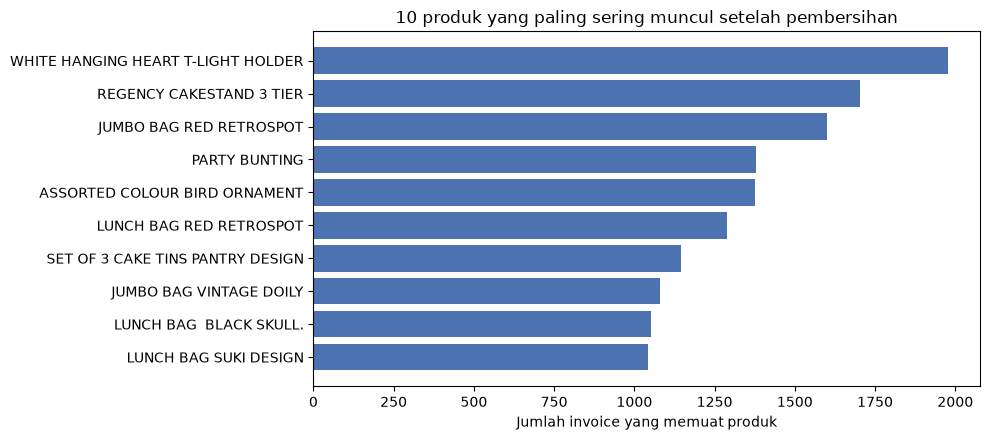

In [8]:
nama_produk = (df.groupby("StockCode")["Description"]
                 .agg(lambda s: s.value_counts().idxmax()))

produk_favorit = (df.drop_duplicates(["InvoiceNo", "StockCode"])["StockCode"]
                    .value_counts().head(10))
label_favorit = [nama_produk[k].strip()[:38] for k in produk_favorit.index]

fig, ax = plt.subplots(figsize=(10, 4.5))
ax.barh(label_favorit[::-1], produk_favorit.values[::-1], color="#4C72B0")
ax.set_xlabel("Jumlah invoice yang memuat produk")
ax.set_title("10 produk yang paling sering muncul setelah pembersihan")
plt.tight_layout()
plt.show()

Produk teratas didominasi pernak-pernik dekorasi dan hadiah: *Regency cakestand*, *white hanging heart t-light holder*, *party bunting*, dan *jumbo bag*. Dataset ini memang berasal dari pengecer giftware, bukan minimarket, sehingga pola berulang lebih mungkin berupa pembelian ulang untuk stok toko kecil atau hadiah musiman.

## 3. Persiapan Data untuk Sequential Pattern Mining

Langkah penyusunan sequence:

1. Urutkan baris berdasarkan `CustomerID` dan `InvoiceDate`.
2. Kelompokkan semua produk dalam satu `InvoiceNo` menjadi satu **itemset**. Urutan produk di dalam itemset tidak penting, sehingga item disimpan sebagai himpunan terurut.
3. Gabungkan itemset pelanggan menurut waktu menjadi satu **sequence**: daftar itemset yang urut secara kronologis.

Hasil akhirnya adalah `list of list of itemset`, yaitu `list[list[tuple[str, ...]]]`.

In [9]:
urut = (df.groupby(["CustomerID", "InvoiceNo"])
          .agg(itemset=("StockCode", lambda s: tuple(sorted(set(s)))),
               waktu=("InvoiceDate", "min"))
          .reset_index()
          .sort_values(["CustomerID", "waktu", "InvoiceNo"]))

urutan_pelanggan = urut.groupby("CustomerID")["itemset"].apply(list)
urutan = urutan_pelanggan.tolist()
panjang = urutan_pelanggan.apply(len)

print(f"Jumlah sequence (pelanggan): {len(urutan):,}")
print(f"Panjang sequence  : median {panjang.median():.0f} | rata-rata {panjang.mean():.2f} | maks {panjang.max():,}")
print(f"Pelanggan 1 invoice: {(panjang == 1).sum():,} ({(panjang == 1).mean():.1%})")
print(f"Rata-rata item unik per pelanggan: {np.mean([sum(len(x) for x in s) for s in urutan]):.1f}")

Jumlah sequence (pelanggan): 4,334
Panjang sequence  : median 2 | rata-rata 4.25 | maks 206
Pelanggan 1 invoice: 1,505 (34.7%)
Rata-rata item unik per pelanggan: 89.1


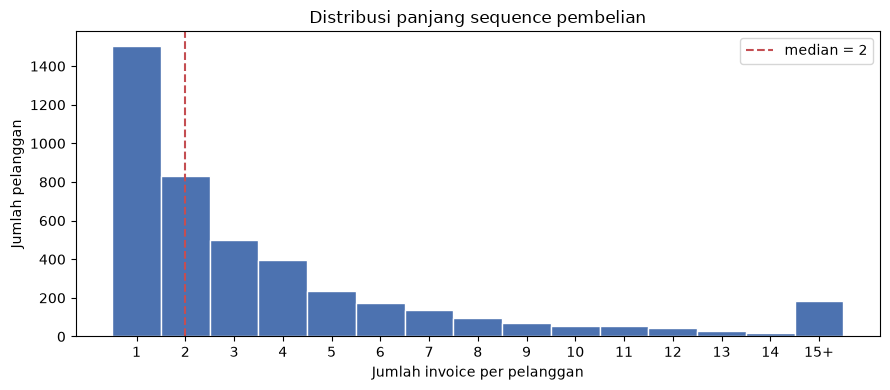

In [10]:
fig, ax = plt.subplots(figsize=(9, 4))
data = panjang.clip(upper=15)
ax.hist(data, bins=np.arange(0.5, 16.5, 1), color="#4C72B0", edgecolor="white")
ax.set_xticks(range(1, 16))
ax.set_xticklabels([str(i) for i in range(1, 15)] + ["15+"])
ax.set_xlabel("Jumlah invoice per pelanggan")
ax.set_ylabel("Jumlah pelanggan")
ax.set_title("Distribusi panjang sequence pembelian")
ax.axvline(panjang.median(), color="#C44E52", linestyle="--",
           label=f"median = {panjang.median():.0f}")
ax.legend()
plt.tight_layout()
plt.show()

Terbentuk **4.334 sequence**. Median panjang sequence hanya **2 invoice**, rata-rata **4,25 invoice**, dan maksimum **206 invoice**. Sebanyak **1.505 pelanggan (34,7%)** hanya memiliki satu invoice sehingga secara definisi tidak dapat membentuk pola panjang dua; mereka tetap dihitung dalam penyebut support agar support mencerminkan seluruh basis pelanggan.

In [11]:
contoh = urutan_pelanggan[panjang.between(3, 5)].head(2)
for cid, seq in contoh.items():
    print(f"Pelanggan {cid} — {len(seq)} invoice")
    for i, itemset in enumerate(seq, 1):
        produk = [nama_produk[k].strip() for k in itemset]
        tampil = "; ".join(produk[:6])
        if len(produk) > 6:
            tampil += f"; ... (+{len(produk) - 6} produk)"
        print(f"  invoice {i}: {tampil}")
    print()

Pelanggan 12348 — 4 invoice
  invoice 1: SET OF 72 SKULL PAPER  DOILIES; PACK OF 72 SKULL CAKE CASES; SWEETIES  STICKERS; PACK OF 60 PINK PAISLEY CAKE CASES; PACK OF 12 WOODLAND TISSUES; PACK OF 12 SUKI TISSUES; ... (+6 produk)
  invoice 2: MULTI HEARTS  STICKERS; PACK OF 12 SKULL TISSUES; PACK OF 12 RED RETROSPOT TISSUES; PACK OF 12 BLUE PAISLEY TISSUES; PACK OF 12 HEARTS DESIGN TISSUES
  invoice 3: SET OF 9 BLACK SKULL BALLOONS; ICE CREAM SUNDAE LIP GLOSS; DOUGHNUT LIP GLOSS; ICE CREAM PEN LIP GLOSS
  invoice 4: DOUGHNUT LIP GLOSS; ICE CREAM PEN LIP GLOSS

Pelanggan 12356 — 3 invoice
  invoice 1: LAVENDER SCENTED FABRIC HEART; WHITE HEART CONFETTI IN TUBE; PINK  HEART CONFETTI IN TUBE; PACK OF 72 SKULL CAKE CASES; SWEETHEART CERAMIC TRINKET BOX; RED RETROSPOT TRADITIONAL TEAPOT; ... (+29 produk)
  invoice 2: PINK BLUE FELT CRAFT TRINKET BOX; SET/20 RED RETROSPOT PAPER NAPKINS; SET/6 RED SPOTTY PAPER CUPS; SET/6 RED SPOTTY PAPER PLATES; SET/10 PINK POLKADOT PARTY CANDLES; SET/10 BLUE 

Contoh di atas memperlihatkan struktur yang dipakai algoritma: setiap baris `invoice` adalah satu itemset, dan urutan invoice membentuk sequence pelanggan. Produk yang dibeli bersamaan tidak diberi urutan internal; yang diurutkan adalah waktu antar-invoice.

## 4. Penerapan Algoritma PrefixSpan

Support sebuah pola berurutan $P$ adalah proporsi pelanggan yang sequence-nya memuat $P$ sebagai subsequence:

$$\text{supp}(P) = \frac{|\{s \in S : P \sqsubseteq s\}|}{|S|}$$

dengan $S$ himpunan seluruh sequence pelanggan. Sebuah pola $P = \langle I_1, I_2, \ldots, I_k \rangle$ muncul pada sequence $s$ jika itemset $I_1$ terjadi lebih dahulu daripada $I_2$, dan seterusnya; item di dalam satu itemset tidak memiliki urutan.

PrefixSpan membangun pola dari prefix yang sudah frequent menggunakan *projected database*. Dua jenis perluasan dipakai:

- **I-step** (*itemset step*): menambahkan itemset baru setelah itemset terakhir, contoh $\langle \{A\} \rangle \rightarrow \langle \{A\}, \{B\} \rangle$.
- **S-step** (*sequence step*): menambahkan item ke itemset terakhir, contoh $\langle \{A\} \rangle \rightarrow \langle \{A, B\} \rangle$.

Paket `prefixspan` di PyPI memodelkan setiap elemen sequence sebagai satu item tunggal, sehingga tidak dapat membedakan produk yang dibeli dalam invoice yang sama dari pembelian berurutan. Implementasi berikut memakai projected database yang mendukung itemset, sesuai kebutuhan langkah praktikum.

In [12]:
def prefixspan(sequences, min_support, minlen=1, maxlen=4):
    '''Mining sequential pattern dengan itemset.

    sequences   : list[list[tuple[str, ...]]]
    min_support : jumlah minimum pelanggan yang memuat pola (absolut)
    minlen      : panjang minimum pola (jumlah itemset)
    maxlen      : panjang maksimum pola (jumlah itemset)
    '''
    kosakata = sorted({item for seq in sequences for itemset in seq for item in itemset})
    id_item = {item: i for i, item in enumerate(kosakata)}
    db = [[tuple(sorted({id_item[item] for item in itemset})) for itemset in seq]
          for seq in sequences]

    hasil = []

    def telusuri(pola, matches):
        if len(pola) >= minlen:
            hasil.append((len(matches), tuple(pola)))

        if len(pola) >= maxlen:
            return

        # I-step: item pertama sesudah itemset terakhir
        kandidat = {}
        for sid, pos in matches:
            sudah = set()
            sekuens = db[sid]
            for p in range(pos + 1, len(sekuens)):
                for item in sekuens[p]:
                    if item not in sudah:
                        sudah.add(item)
                        kandidat.setdefault(item, []).append((sid, p))

        for item, m in kandidat.items():
            if len(m) >= min_support:
                telusuri(pola + [(item,)], m)

        # S-step: item lain di dalam itemset terakhir
        if not pola:
            return

        akhir = set(pola[-1])
        batas = max(akhir)
        kandidat = {}
        for sid, pos in matches:
            sekuens = db[sid]
            ketemu = {}
            for p in range(pos, len(sekuens)):
                if akhir.issubset(sekuens[p]):
                    for item in sekuens[p]:
                        if item > batas and item not in ketemu:
                            ketemu[item] = p
            for item, p in ketemu.items():
                kandidat.setdefault(item, []).append((sid, p))

        for item, m in kandidat.items():
            if len(m) >= min_support:
                telusuri(pola[:-1] + [pola[-1] + (item,)], m)

    telusuri([], [(i, -1) for i in range(len(db))])
    return hasil, kosakata

### Pemilihan minimum support

`min_support = 0,01` adalah titik awal sesuai petunjuk praktikum. Untuk melihat apakah nilai itu menghasilkan pola yang terlalu banyak, ambang diuji pada beberapa nilai. Tabel berikut memakai `maxlen = 2` agar semua ambang dibandingkan pada ruang pola yang sama dan biaya komputasi tetap wajar; pola final nanti memakai `maxlen = 4`.

In [13]:
def hitung_pola(fraksi, maxlen=2):
    ambang = int(np.ceil(fraksi * len(urutan)))
    hasil, _ = prefixspan(urutan, ambang, minlen=2, maxlen=maxlen)
    return ambang, len(hasil)

baris = []
for fraksi in [0.01, 0.02, 0.03, 0.05]:
    ambang, jumlah = hitung_pola(fraksi)
    baris.append({"min_support": fraksi,
                  "ambang pelanggan": ambang,
                  "jumlah pola (maxlen=2)": jumlah})

tabel_sensitivitas = pd.DataFrame(baris)
tabel_sensitivitas

,min_support,ambang pelanggan,jumlah pola (maxlen=2)
0,0.01,44,29876
1,0.02,87,2116
2,0.03,131,337
3,0.05,217,11


Dengan `min_support = 0,01`, bahkan pada `maxlen = 2` sudah dihasilkan **29.876 pola**. Jumlah itu terlalu besar untuk diperiksa, diurutkan, dan diinterpretasikan dalam laporan singkat. Pada `0,02` jumlahnya turun menjadi **2.116 pola**, tetapi masih jauh lebih banyak daripada yang dapat dibahas secara manual.

`min_support = 0,03` (minimal **131 pelanggan**) menyisakan **337 pola** pada `maxlen = 2`, lalu **377 pola** pada `maxlen = 4`. Jumlah ini cukup kaya untuk melihat variasi pola, tetapi masih bisa diurutkan dan diambil tiga pola teratas. Nilai `0,05` hanya menyisakan **11 pola** sehingga terlalu sedikit untuk analisis. Karena itu `0,03` dipakai sebagai parameter final.

In [14]:
MIN_SUPPORT = 0.03
AMBANG = int(np.ceil(MIN_SUPPORT * len(urutan)))

pola, kosakata = prefixspan(urutan, AMBANG, minlen=1, maxlen=4)
pola_berurutan = [(s, p) for s, p in pola if len(p) >= 2]

print(f"min_support = {MIN_SUPPORT} -> minimal {AMBANG} pelanggan")
print(f"Pola dengan panjang >= 2 itemset: {len(pola_berurutan):,}")
print("Sebaran panjang pola:", dict(sorted(Counter(len(p) for _, p in pola_berurutan).items())))

min_support = 0.03 -> minimal 131 pelanggan
Pola dengan panjang >= 2 itemset: 377
Sebaran panjang pola: {2: 364, 3: 12, 4: 1}


In [15]:
def teks_pola(pola):
    return " → ".join(
        "{" + ", ".join(nama_produk[kosakata[i]].strip() for i in itemset) + "}"
        for itemset in pola
    )

support_pola = {tuple(p): s for s, p in pola}

tabel_pola = pd.DataFrame({
    "pola": [teks_pola(p) for _, p in pola_berurutan],
    "panjang": [len(p) for _, p in pola_berurutan],
    "n_pelanggan": [s for s, _ in pola_berurutan],
    "support": [s / len(urutan) for s, _ in pola_berurutan],
    "lintas_produk": [len({kosakata[i] for itemset in p for i in itemset}) > 1
                      for _, p in pola_berurutan],
})
tabel_pola["confidence"] = [
    s / support_pola[tuple(p[:-1])] for s, p in pola_berurutan
]
tabel_pola = (tabel_pola.sort_values(["support", "confidence"], ascending=False)
                          .reset_index(drop=True))

def tabel_pola_html(data):
    return HTML(data.to_html(index=False, classes="tabel-pola", border=0,
                             float_format=lambda v: f"{v:.4f}"))

tabel_pola_html(tabel_pola.head(20)[["pola", "support", "confidence", "n_pelanggan"]])

pola,support,confidence,n_pelanggan
{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE HANGING HEART T-LIGHT HOLDER},0.0939,0.4755,407
{REGENCY CAKESTAND 3 TIER} → {REGENCY CAKESTAND 3 TIER},0.0761,0.3746,330
{JUMBO BAG RED RETROSPOT} → {JUMBO BAG RED RETROSPOT},0.0720,0.4913,312
{ASSORTED COLOUR BIRD ORNAMENT} → {ASSORTED COLOUR BIRD ORNAMENT},0.0671,0.4292,291
{PARTY BUNTING} → {PARTY BUNTING},0.0646,0.3955,280
{LUNCH BAG RED RETROSPOT} → {LUNCH BAG RED RETROSPOT},0.0637,0.5188,276
{JUMBO BAG RED RETROSPOT} → {JUMBO BAG VINTAGE DOILY},0.0545,0.3717,236
{JUMBO BAG VINTAGE DOILY} → {JUMBO BAG VINTAGE DOILY},0.0535,0.4594,232
{LUNCH BAG BLACK SKULL.} → {LUNCH BAG BLACK SKULL.},0.0528,0.5000,229
{LUNCH BAG SUKI DESIGN} → {LUNCH BAG SUKI DESIGN},0.0521,0.5207,226


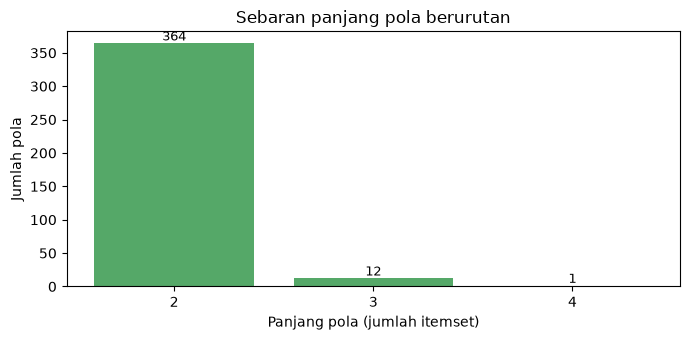

In [16]:
fig, ax = plt.subplots(figsize=(7, 3.5))
dist = tabel_pola["panjang"].value_counts().sort_index()
ax.bar(dist.index.astype(str), dist.values, color="#55A868")
for i, v in enumerate(dist.values):
    ax.text(i, v, f"{v:,}", ha="center", va="bottom", fontsize=9)
ax.set_xlabel("Panjang pola (jumlah itemset)")
ax.set_ylabel("Jumlah pola")
ax.set_title("Sebaran panjang pola berurutan")
plt.tight_layout()
plt.show()

Mayoritas pola berpanjang dua itemset (**364 dari 377**), diikuti 12 pola panjang tiga dan 1 pola panjang empat. Pola yang lebih panjang jarang muncul karena setiap tambahan itemset menuntut urutan pembelian yang sama pada lebih banyak pelanggan. Sebanyak **57 pola** memuat itemset berisi lebih dari satu produk; pola inilah yang menangkap pembelian beberapa produk dalam invoice yang sama, bukan hanya perpindahan antar-invoice.

## 5. Evaluasi Pola Berurutan

Support mengukur seberapa luas pola menjangkau basis pelanggan, tetapi tidak mengukur seberapa kuat kelanjutannya. Confidence pola $P$ dihitung sebagai:

$$\text{conf}(P) = \frac{\text{supp}(P)}{\text{supp}(P^{-})}$$

dengan $P^{-}$ adalah pola $P$ tanpa itemset terakhir. Untuk pola dua itemset $\langle \{A\}, \{B\} \rangle$, confidence berarti: di antara pelanggan yang pernah membeli $A$, berapa proporsi yang kemudian membeli $B$ pada invoice berikutnya. Pola satu itemset tidak memiliki $P^{-}$ sehingga tidak dievaluasi confidence-nya.

In [17]:
tabel_pola_html(
    tabel_pola.sort_values(["confidence", "support"], ascending=False)
               .head(10)[["pola", "support", "confidence", "n_pelanggan"]]
)

pola,support,confidence,n_pelanggan
{JUMBO BAG RED RETROSPOT} → {LUNCH BAG RED RETROSPOT} → {JUMBO BAG RED RETROSPOT},0.0309,0.6700,134
{JUMBO BAG RED RETROSPOT} → {JUMBO BAG VINTAGE DOILY} → {JUMBO BAG RED RETROSPOT},0.0362,0.6653,157
"{LUNCH BAG RED RETROSPOT, JUMBO BAG RED RETROSPOT} → {JUMBO BAG RED RETROSPOT}",0.0325,0.6558,141
"{LUNCH BAG RED RETROSPOT, LUNCH BAG WOODLAND} → {LUNCH BAG RED RETROSPOT}",0.0321,0.6526,139
"{LUNCH BAG BLACK SKULL., LUNCH BAG CARS BLUE} → {LUNCH BAG BLACK SKULL.}",0.0307,0.6488,133
{JUMBO BAG RED RETROSPOT} → {JUMBO BAG VINTAGE DOILY} → {JUMBO BAG VINTAGE DOILY},0.0344,0.6314,149
{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE HANGING HEART T-LIGHT HOLDER},0.0323,0.6250,140
"{LUNCH BAG BLACK SKULL., LUNCH BAG SUKI DESIGN} → {LUNCH BAG BLACK SKULL.}",0.0316,0.6199,137
"{LUNCH BAG RED RETROSPOT, LUNCH BAG SUKI DESIGN} → {LUNCH BAG SUKI DESIGN}",0.0348,0.6113,151
"{LUNCH BAG BLACK SKULL., LUNCH BAG SUKI DESIGN} → {LUNCH BAG SUKI DESIGN}",0.0311,0.6109,135


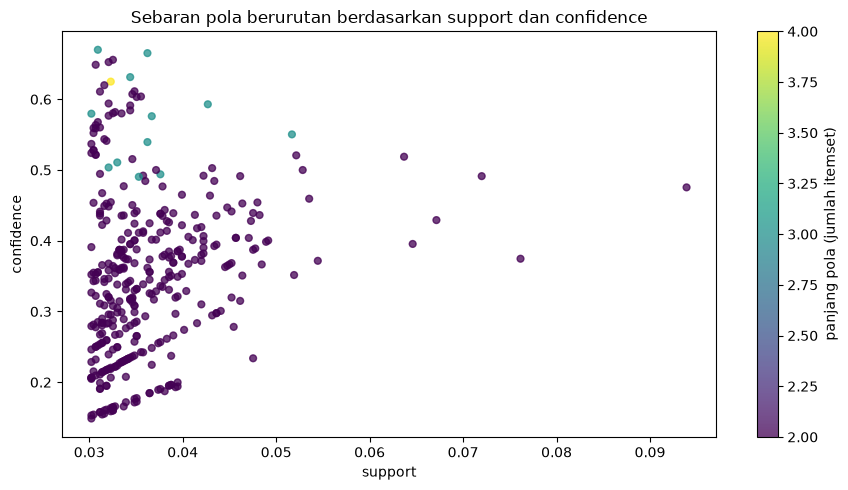

In [18]:
fig, ax = plt.subplots(figsize=(9, 5))
titik = ax.scatter(tabel_pola["support"], tabel_pola["confidence"],
                   c=tabel_pola["panjang"], cmap="viridis", s=24, alpha=0.75)
ax.set_xlabel("support")
ax.set_ylabel("confidence")
ax.set_title("Sebaran pola berurutan berdasarkan support dan confidence")
fig.colorbar(titik, ax=ax, label="panjang pola (jumlah itemset)")
plt.tight_layout()
plt.show()

Sebaran confidence bergerak dari **14,9%** sampai **67,0%** dengan median **35,2%**. Pola dengan support tinggi cenderung memiliki confidence sedang (35–55%): pembelian ulang produk yang sama lebih luas jangkauannya, tetapi tidak selalu menjadi kelanjutan yang dominan. Confidence tertinggi justru dimiliki beberapa pola panjang tiga dan pola yang memuat kombinasi produk dalam satu itemset, yang jangkauannya lebih sempit.

### Tiga pola terbaik berdasarkan support

In [19]:
tabel_pola_html(tabel_pola.head(3)[["pola", "support", "confidence", "n_pelanggan"]])

pola,support,confidence,n_pelanggan
{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE HANGING HEART T-LIGHT HOLDER},0.0939,0.4755,407
{REGENCY CAKESTAND 3 TIER} → {REGENCY CAKESTAND 3 TIER},0.0761,0.3746,330
{JUMBO BAG RED RETROSPOT} → {JUMBO BAG RED RETROSPOT},0.0720,0.4913,312


**1. `{WHITE HANGING HEART T-LIGHT HOLDER} → {WHITE HANGING HEART T-LIGHT HOLDER}`**  
Support **9,39%** (407 dari 4.334 pelanggan) · confidence **47,5%** · 856 pelanggan pernah membeli produk ini sedikitnya sekali.

Dari 856 pelanggan yang pernah membeli *white hanging heart t-light holder*, 407 membelinya lagi pada invoice berbeda dalam periode satu tahun. Produk dekorasi hati ini berfungsi sebagai hadiah atau stok display toko kecil; pola pembelian ulangnya menunjukkan kebutuhan restock, bukan pembelian sekali pakai. Tindakan yang masuk akal adalah pengingat restock atau diskon bertingkat untuk pembelian kedua, bukan promosi massal—jangkauannya tetap di bawah 10% pelanggan.

**2. `{REGENCY CAKESTAND 3 TIER} → {REGENCY CAKESTAND 3 TIER}`**  
Support **7,61%** (330 pelanggan) · confidence **37,5%** · 881 pelanggan pernah membeli produk ini.

*Regency cakestand 3 tier* adalah produk bernilai lebih tinggi dan menjadi produk dengan jumlah pembeli terbanyak dalam data bersih. Sebanyak 330 pelanggan membelinya pada lebih dari satu invoice, tetapi confidence 37,5% lebih rendah daripada dua pola lain. Artinya, pembelian ulang produk ini lebih tersebar dan tidak sekuat pola jumbo bag. Pelanggannya kemungkinan toko kue, katering, atau penyelenggara acara yang membeli beberapa unit pada waktu berbeda.

**3. `{JUMBO BAG RED RETROSPOT} → {JUMBO BAG RED RETROSPOT}`**  
Support **7,20%** (312 pelanggan) · confidence **49,1%** · 635 pelanggan pernah membeli produk ini.

Hampir separuh pelanggan yang pernah membeli *jumbo bag red retrospot* membelinya lagi. Sebagai tas hadiah berharga rendah, produk ini paling dekat dengan pola **replenishment**: habis dipakai, lalu dibeli lagi. Pola ini juga terhubung dengan varian jumbo bag lain: `{JUMBO BAG RED RETROSPOT} → {JUMBO BAG VINTAGE DOILY}` memiliki support 5,45% dan confidence 37,2%, sedangkan pola bergantian `{JUMBO BAG RED RETROSPOT} → {JUMBO BAG VINTAGE DOILY} → {JUMBO BAG RED RETROSPOT}` mencapai confidence 66,5%. Untuk bisnis, ini mendukung strategi bundling beberapa motif dan diskon pembelian ulang.

### Pola lintas produk

Tiga pola dengan support tertinggi seluruhnya berupa pembelian ulang produk yang sama. Untuk melihat perpindahan antar-produk, tabel berikut menyaring pola yang memuat sedikitnya dua `StockCode` berbeda dan mengurutkannya berdasarkan support.

In [20]:
tabel_lintas = (tabel_pola[tabel_pola["lintas_produk"]]
                .sort_values(["support", "confidence"], ascending=False))
tabel_pola_html(tabel_lintas.head(10)[["pola", "support", "confidence", "n_pelanggan"]])

pola,support,confidence,n_pelanggan
{JUMBO BAG RED RETROSPOT} → {JUMBO BAG VINTAGE DOILY},0.0545,0.3717,236
{LUNCH BAG RED RETROSPOT} → {LUNCH BAG VINTAGE DOILY},0.0491,0.4004,213
{LUNCH BAG RED RETROSPOT} → {LUNCH BAG BLACK SKULL.},0.0489,0.3985,212
{LUNCH BAG CARS BLUE} → {LUNCH BAG RED RETROSPOT},0.0482,0.4363,209
{LUNCH BAG BLACK SKULL.} → {LUNCH BAG RED RETROSPOT},0.0480,0.4541,208
{LUNCH BAG RED RETROSPOT} → {LUNCH BAG SPACEBOY DESIGN},0.0478,0.3891,207
{LUNCH BAG RED RETROSPOT} → {LUNCH BAG SUKI DESIGN},0.0475,0.3872,206
{REGENCY CAKESTAND 3 TIER} → {SET OF 3 REGENCY CAKE TINS},0.0475,0.2338,206
{JUMBO BAG VINTAGE DOILY} → {JUMBO BAG RED RETROSPOT},0.0471,0.4040,204
{LUNCH BAG PINK POLKADOT} → {LUNCH BAG RED RETROSPOT},0.0464,0.4527,201


Pola lintas produk terkuat terkonsentrasi pada **koleksi produk yang sama**: lunch bag dengan berbagai motif, jumbo bag dengan berbagai motif, party bunting, dan alarm clock warna. Contohnya:

- `{LUNCH BAG RED RETROSPOT} → {LUNCH BAG VINTAGE DOILY}` — support 4,91%, confidence 40,0%.
- `{LUNCH BAG CARS BLUE} → {LUNCH BAG RED RETROSPOT}` — support 4,82%, confidence 43,6%.
- `{CANDLEHOLDER PINK HANGING HEART} → {WHITE HANGING HEART T-LIGHT HOLDER}` — support 3,16%, confidence 54,4%.

Pola-pola ini lebih lemah daripada pembelian ulang produk tunggal, tetapi lebih actionable untuk *cross-selling*: pelanggan cenderung melengkapi koleksi motif atau warna, bukan berpindah ke kategori produk yang sama sekali berbeda.

## 6. Kesimpulan

1. **Kualitas data menentukan jumlah sequence.** Dari 541.909 baris mentah, pembersihan menyisakan 396.337 baris (73,1%), 18.402 invoice, 4.334 pelanggan, dan 3.659 produk. Tanpa membuang invoice batal, retur, dan item non-produk, pola yang muncul akan didominasi ongkir dan penyesuaian akuntansi, bukan pembelian produk.

2. **`min_support = 0,01` terlalu rendah untuk dataset ini.** Bahkan dengan `maxlen = 2`, ambang tersebut menghasilkan 29.876 pola. Pada `0,03` jumlahnya turun menjadi 337 pola (`maxlen = 2`) dan 377 pola (`maxlen = 4`), sehingga masih bisa diperiksa dan diinterpretasikan. Ambang 0,05 terlalu agresif karena hanya menyisakan 11 pola.

3. **Sinyal sequential terkuat adalah pembelian ulang, bukan perpindahan kategori.** Tiga pola dengan support tertinggi seluruhnya berbentuk $A \rightarrow A$: white hanging heart t-light holder (9,39%, confidence 47,5%), Regency cakestand 3 tier (7,61%, confidence 37,5%), dan jumbo bag red retrospot (7,20%, confidence 49,1%). Pola ini konsisten dengan perilaku restock barang dekorasi dan tas hadiah.

4. **Pola lintas produk membentuk efek koleksi.** Setelah pembelian ulang produk tunggal, pola terkuat adalah perpindahan antar-motif dalam keluarga produk yang sama, misalnya lunch bag dan jumbo bag. Pelanggan cenderung menambah variasi motif, sehingga bundling beberapa motif lebih masuk akal daripada promosi kategori yang jauh berbeda.

5. **Keterbatasan analisis.** Sequence hanya mencakup pelanggan yang memiliki `CustomerID`; 135.080 baris tanpa ID tidak dapat dimasukkan. Support dihitung terhadap seluruh 4.334 pelanggan, termasuk 1.505 pelanggan yang hanya memiliki satu invoice, sehingga support pola panjang dua bersifat konservatif. Pola juga dibatasi oleh periode data satu tahun, pemakaian `StockCode` sebagai identitas produk, dan `maxlen = 4`. Confidence menunjukkan kekuatan asosiasi berurutan, bukan hubungan kausal; faktor musim, harga, dan promosi belum dimodelkan.

## Referensi

- Chen, D., Sain, S. L., & Guo, K. (2012). Data mining for the online retail industry: A case study of RFM model-based customer segmentation using data mining. *Journal of Database Marketing & Customer Strategy Management*, 19(3), 197–208.
- Pei, J., Han, J., Mortazavi-Asl, B., Pinto, H., Chen, Q., Dayal, U., & Hsu, M.-C. (2001). PrefixSpan: Mining sequential patterns efficiently by prefix-projected pattern growth. *Proceedings of the 17th International Conference on Data Engineering (ICDE)*, 215–224.
- UCI Machine Learning Repository. *Online Retail* dataset. https://archive.ics.uci.edu/dataset/352/online+retail